# 37 · Motion planning: RRT-Connect in the Panda's joint space with MuJoCo collision checks

In [1]:
import time, mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt
from vlacourse import add_ee_site, solve_ik, yaw_quat, show_video

def scene():
    spec = mm.get("franka_emika_panda").spec("scene"); add_ee_site(spec)
    spec.geom("floor").pos = [0, 0, -0.75]
    wb = spec.worldbody
    wb.add_geom(name="table", type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.5, 0.65, 0.375], pos=[0.4, 0, -0.375], rgba=[0.55, 0.42, 0.3, 1])
    wb.add_geom(name="wall", type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.12, 0.02, 0.22], pos=[0.5, 0, 0.22], rgba=[0.8, 0.2, 0.2, 0.8])
    wb.add_geom(name="shelf", type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.15, 0.25, 0.01], pos=[0.5, 0, 0.6], rgba=[0.3, 0.3, 0.8, 0.6])
    m = spec.compile(); d = mujoco.MjData(m)
    mujoco.mj_resetDataKeyframe(m, d, 0); mujoco.mj_forward(m, d)
    return m, d

class Checker:
    def __init__(self, model, clearance=0.01, padded=("wall", "shelf")):
        self.m = model.__copy__()
        self.d, self.clearance = mujoco.MjData(self.m), clearance
        self.padded = {self.m.geom(n).id for n in padded}
        for g in self.padded:
            self.m.geom_margin[g] = clearance
        self.robot = {model.body(n).id for n in ["link1", "link2", "link3", "link4", "link5", "link6", "link7", "hand", "left_finger", "right_finger"]}
        self.lo, self.hi = model.jnt_range[:7, 0], model.jnt_range[:7, 1]
        self.calls = 0

    def free(self, q):
        self.calls += 1
        if np.any(q < self.lo) or np.any(q > self.hi):
            return False
        self.d.qpos[:7] = q; self.d.qpos[7:9] = 0.04
        mujoco.mj_kinematics(self.m, self.d); mujoco.mj_collision(self.m, self.d)
        for c in self.d.contact[:self.d.ncon]:
            b1, b2 = self.m.geom_bodyid[c.geom1], self.m.geom_bodyid[c.geom2]
            limit = self.clearance if (c.geom1 in self.padded or c.geom2 in self.padded) else 0.0
            if (b1 in self.robot) != (b2 in self.robot) and c.dist < limit:
                return False
        return True

    def edge_free(self, a, b, step=0.05):
        n = int(np.ceil(np.max(np.abs(b - a)) / step))
        return all(self.free(a + (b - a) * k / n) for k in range(1, n + 1))

def rrt_connect(chk, q_start, q_goal, rng, step=0.3, max_iter=8000):
    trees = [{0: (q_start, None)}, {0: (q_goal, None)}]
    def nearest(T, q):
        keys = list(T); X = np.array([T[k][0] for k in keys])
        return keys[np.argmin(np.linalg.norm(X - q, axis=1))]
    def extend(T, q):
        k = nearest(T, q); qn = T[k][0]
        d = q - qn; dist = np.linalg.norm(d)
        q_new = q if dist < step else qn + d / dist * step
        if chk.edge_free(qn, q_new):
            T[len(T)] = (q_new, k); return len(T) - 1, np.allclose(q_new, q)
        return None, False
    for it in range(max_iter):
        q_rand = rng.uniform(chk.lo, chk.hi)
        a, b = trees[it % 2], trees[(it + 1) % 2]
        ka, _ = extend(a, q_rand)
        if ka is None:
            continue
        while True:
            kb, reached = extend(b, a[ka][0])
            if kb is None:
                break
            if reached:
                def path(T, k):
                    out = []
                    while k is not None:
                        out.append(T[k][0]); k = T[k][1]
                    return out
                pa, pb = path(a, ka), path(b, kb)
                full = pa[::-1] + pb if it % 2 == 0 else pb[::-1] + pa
                return np.array(full), it, len(a) + len(b)
    return None, max_iter, len(trees[0]) + len(trees[1])

def shortcut(chk, path, rng, n=200):
    path = list(path)
    for _ in range(n):
        if len(path) < 3:
            break
        i, j = sorted(rng.choice(len(path), 2, replace=False))
        if j - i > 1 and chk.edge_free(path[i], path[j]):
            path = path[:i + 1] + path[j:]
    return np.array(path)

def ee_points(model, data, path, sub=10):
    pts = []
    for a, b in zip(path[:-1], path[1:]):
        for s in np.linspace(0, 1, sub):
            data.qpos[:7] = a + s * (b - a); mujoco.mj_kinematics(model, data); pts.append(data.site("ee").xpos.copy())
    return np.array(pts)

In [2]:
model, data = scene()
chk = Checker(model)
q_start, _ = solve_ik(model, data, np.array([0.5, -0.2, 0.15]), yaw_quat(0.0), data.qpos[:7])
q_goal, _ = solve_ik(model, data, np.array([0.5, 0.2, 0.15]), yaw_quat(0.0), q_start)
print("start free:", chk.free(q_start), "| goal free:", chk.free(q_goal), "| straight joint line free:", chk.edge_free(q_start, q_goal))

start free: True | goal free: True | straight joint line free: False


In [3]:
rng = np.random.default_rng(0)
t0 = time.perf_counter()
path, iters, nodes = rrt_connect(chk, q_start, q_goal, rng)
t_plan = time.perf_counter() - t0
short = shortcut(chk, path, rng)
print(f"RRT-Connect: {iters} iterations, {nodes} nodes, {chk.calls} collision checks, {t_plan:.2f} s")
print(f"waypoints: raw {len(path)} -> shortcut {len(short)} | joint path length {np.sum(np.linalg.norm(np.diff(path, axis=0), axis=1)):.2f} -> {np.sum(np.linalg.norm(np.diff(short, axis=0), axis=1)):.2f} rad")

RRT-Connect: 258 iterations, 158 nodes, 2270 collision checks, 0.07 s
waypoints: raw 40 -> shortcut 5 | joint path length 11.25 -> 7.02 rad


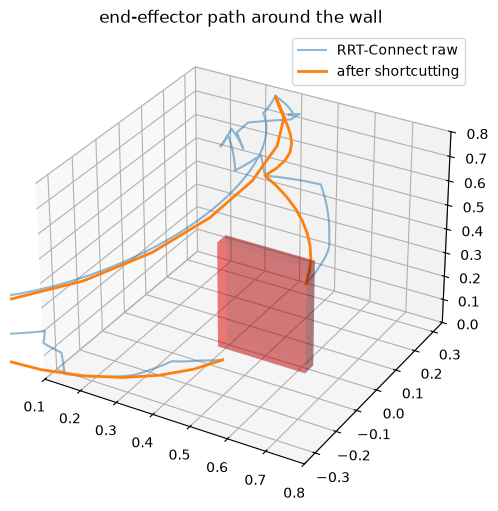

In [4]:
P_raw, P_short = ee_points(model, data, path), ee_points(model, data, short)
fig = plt.figure(figsize=(7, 6)); ax = fig.add_subplot(projection="3d")
ax.plot(*P_raw.T, alpha=0.5, label="RRT-Connect raw"); ax.plot(*P_short.T, lw=2, label="after shortcutting")
ax.bar3d(0.38, -0.02, 0, 0.24, 0.04, 0.44, color="r", alpha=0.3)
ax.set_xlim(0.1, 0.8); ax.set_ylim(-0.35, 0.35); ax.set_zlim(0, 0.8); ax.legend(); ax.set_title("end-effector path around the wall"); plt.show()

In [5]:
def execute(model, data, path, rad_per_step, render=False):
    names = {model.geom(n).id: n for n in ["wall", "shelf"]}
    hits, frames, dev = set(), [], 0.0
    r = mujoco.Renderer(model, 300, 400) if render else None
    mujoco.mj_resetDataKeyframe(model, data, 0); data.qpos[:7] = path[0]; data.ctrl[:7] = path[0]; mujoco.mj_forward(model, data)
    for a, b in zip(path[:-1], path[1:]):
        n = int(np.max(np.abs(b - a)) / rad_per_step) + 1
        for k in range(n):
            data.ctrl[:7] = a + (b - a) * (k + 1) / n; data.ctrl[7] = 255
            mujoco.mj_step(model, data, 2)
            dev = max(dev, np.abs(data.qpos[:7] - data.ctrl[:7]).max())
            hits |= {names[g] for c in data.contact[:data.ncon] for g in (c.geom1, c.geom2) if g in names}
            if render and k % 6 == 0:
                cam = mujoco.MjvCamera(); cam.lookat[:] = [0.45, 0, 0.25]; cam.distance, cam.azimuth, cam.elevation = 1.6, 135, -25
                r.update_scene(data, cam); frames.append(r.render())
    return hits, dev, frames

for speed in [0.004, 0.0015]:
    hits, dev, _ = execute(model, data, short, speed)
    print(f"execution at {speed / 0.004:.2f}x speed: max servo lag {np.degrees(dev):.1f} deg, obstacle contacts: {hits or 'none'}")

execution at 1.00x speed: max servo lag 5.6 deg, obstacle contacts: none


execution at 0.38x speed: max servo lag 2.1 deg, obstacle contacts: none


saved outputs/37_rrt_connect_plan.mp4  (1.2 MB)


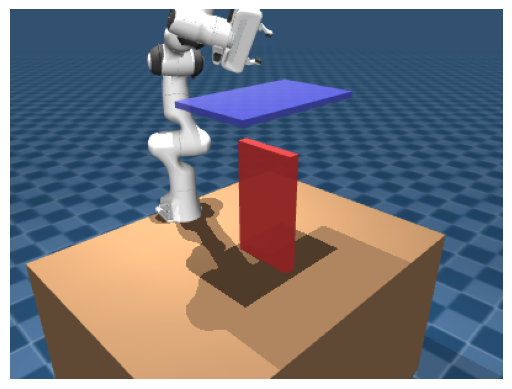

In [6]:
_, _, frames = execute(model, data, short, 0.0015, render=True)
show_video(frames, fps=30, title="RRT-Connect plan")
from vlacourse import showcase as sc
sc.export(frames, "outputs/37_rrt_connect_plan.mp4", fps=30)   # a copy for slides (show_video above already embeds it)
plt.imshow(frames[len(frames) // 2]); plt.axis("off"); plt.show()